In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

from google.colab import files

uploaded = files.upload()


Saving PNRao_HR_Analytics_Complete_Dataset.xlsx to PNRao_HR_Analytics_Complete_Dataset.xlsx


In [ ]:

import io

filename = next(iter(uploaded))

df = pd.read_excel(io.BytesIO(uploaded[filename]))

print("Excel file loaded successfully!")
print("Filename:", filename)
print("Dataset size:", df.shape)

df.head()


Excel file loaded successfully!
Filename: PNRao_HR_Analytics_Complete_Dataset.xlsx
Dataset size: (500, 12)


,EmployeeID,FullName,Department,JobTitle,Email,Gender,HireDate,TerminationDate,Salary,ManagerID,PerformanceRating,Status
0,PNR-1001,Rohan Smith,Finance,Accountant,employee.1001@pnrao.com,Male,2019-10-19,NaN,65504,PNR-1302,3,Active
1,PNR-1002,Emma Wilson,Marketing,Marketing Coordinator,employee.1002@pnrao.com,Female,2019-06-16,NaN,81613,PNR-1081,4,Active
2,PNR-1003,Emma Jones,Production,Line Supervisor,employee.1003@pnrao.com,Female,2021-08-04,2022-04-24,82326,PNR-1148,5,Terminated
3,PNR-1004,Chris Brown,Sales,Regional Sales Manager,employee.1004@pnrao.com,Non-binary,2018-10-09,NaN,134925,NaN,2,Active
4,PNR-1005,Priya Wilson,Quality Control,QC Manager,employee.1005@pnrao.com,Male,2019-02-04,NaN,150999,NaN,4,Active


In [ ]:

print("Dataset shape:", df.shape)


Dataset shape: (500, 12)


In [ ]:

print(df.columns.tolist())


['EmployeeID', 'FullName', 'Department', 'JobTitle', 'Email', 'Gender', 'HireDate', 'TerminationDate', 'Salary', 'ManagerID', 'PerformanceRating', 'Status']


In [ ]:

df.head()


,EmployeeID,FullName,Department,JobTitle,Email,Gender,HireDate,TerminationDate,Salary,ManagerID,PerformanceRating,Status
0,PNR-1001,Rohan Smith,Finance,Accountant,employee.1001@pnrao.com,Male,2019-10-19,NaN,65504,PNR-1302,3,Active
1,PNR-1002,Emma Wilson,Marketing,Marketing Coordinator,employee.1002@pnrao.com,Female,2019-06-16,NaN,81613,PNR-1081,4,Active
2,PNR-1003,Emma Jones,Production,Line Supervisor,employee.1003@pnrao.com,Female,2021-08-04,2022-04-24,82326,PNR-1148,5,Terminated
3,PNR-1004,Chris Brown,Sales,Regional Sales Manager,employee.1004@pnrao.com,Non-binary,2018-10-09,NaN,134925,NaN,2,Active
4,PNR-1005,Priya Wilson,Quality Control,QC Manager,employee.1005@pnrao.com,Male,2019-02-04,NaN,150999,NaN,4,Active


In [ ]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   EmployeeID         500 non-null    object
 1   FullName           500 non-null    object
 2   Department         500 non-null    object
 3   JobTitle           500 non-null    object
 4   Email              500 non-null    object
 5   Gender             500 non-null    object
 6   HireDate           500 non-null    object
 7   TerminationDate    92 non-null     object
 8   Salary             500 non-null    int64 
 9   ManagerID          395 non-null    object
 10  PerformanceRating  500 non-null    int64 
 11  Status             500 non-null    object
dtypes: int64(2), object(10)
memory usage: 47.0+ KB


In [ ]:

print(df.isnull().sum())


EmployeeID             0
FullName               0
Department             0
JobTitle               0
Email                  0
Gender                 0
HireDate               0
TerminationDate      408
Salary                 0
ManagerID            105
PerformanceRating      0
Status                 0
dtype: int64


In [ ]:
print(df["Status"].value_counts())

Status
Active        408
Terminated     92
Name: count, dtype: int64


In [ ]:
# Calculate the termination rate
total_employees = len(df)

terminated_employees = (df["Status"] == "Terminated").sum()

termination_rate = (terminated_employees / total_employees) * 100

print("Total Employees:", total_employees)
print("Terminated Employees:", terminated_employees)
print("Termination Rate:", round(termination_rate, 2), "%")

Total Employees: 500
Terminated Employees: 92
Termination Rate: 18.4 %


In [ ]:
terminated_df = df[df["Status"] == "Terminated"]

print(terminated_df.shape)

(92, 12)


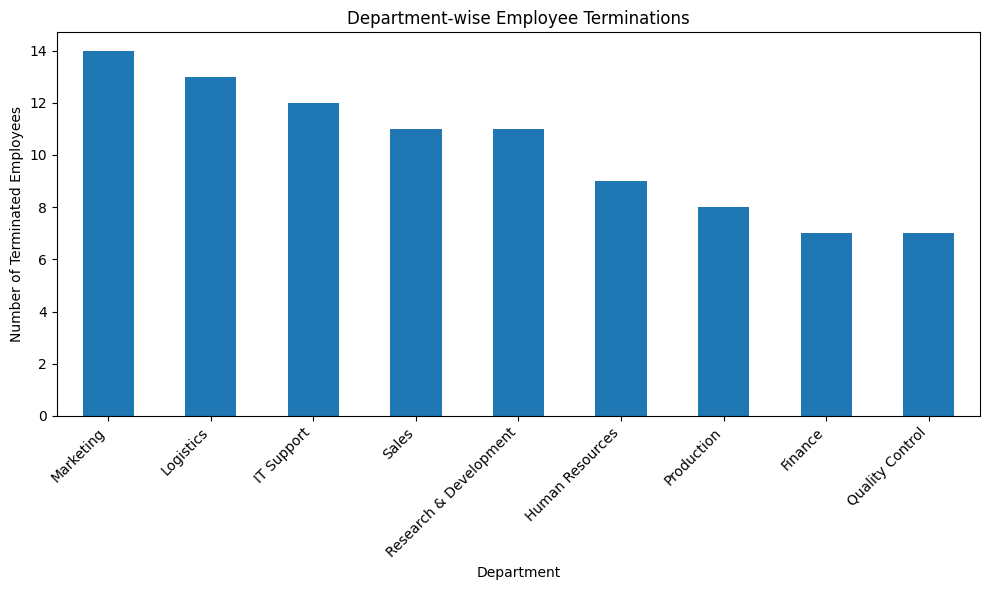

In [ ]:
# Department wise Employee Termination
import matplotlib.pyplot as plt

department_terminations = terminated_df["Department"].value_counts()

plt.figure(figsize=(10, 6))
department_terminations.plot(kind="bar")

plt.title("Department-wise Employee Terminations")
plt.xlabel("Department")
plt.ylabel("Number of Terminated Employees")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [ ]:
# Calculate termination rates by department
department_analysis = df.groupby("Department").agg(
    Total_Employees=("EmployeeID", "count"),
    Terminated_Employees=("Status", lambda x: (x == "Terminated").sum())
)

department_analysis["Termination_Rate"] = (
    department_analysis["Terminated_Employees"]
    / department_analysis["Total_Employees"] * 100
).round(2)

print(department_analysis.sort_values(
    "Termination_Rate", ascending=False
))


                        Total_Employees  Terminated_Employees  \
Department                                                      
Logistics                            57                    13   
Marketing                            64                    14   
Human Resources                      42                     9   
IT Support                           60                    12   
Sales                                57                    11   
Research & Development               62                    11   
Production                           51                     8   
Quality Control                      47                     7   
Finance                              60                     7   

                        Termination_Rate  
Department                                
Logistics                          22.81  
Marketing                          21.88  
Human Resources                    21.43  
IT Support                         20.00  
Sales                     

In [ ]:
#Analyse average salary by department
salary_analysis = df.groupby("Department").agg(
    Employee_Count=("EmployeeID", "count"),
    Average_Salary=("Salary", "mean"),
    Total_Payroll=("Salary", "sum")
)

salary_analysis["Average_Salary"] = salary_analysis["Average_Salary"].round(2)

print(salary_analysis.sort_values("Average_Salary", ascending=False))

                        Employee_Count  Average_Salary  Total_Payroll
Department                                                           
Sales                               57       122331.28        6972883
Quality Control                     47       104053.15        4890498
IT Support                          60        92697.18        5561831
Marketing                           64        91697.36        5868631
Production                          51        88265.47        4501539
Research & Development              62        84786.02        5256733
Logistics                           57        70678.53        4028676
Human Resources                     42        70033.38        2941402
Finance                             60        68485.65        4109139


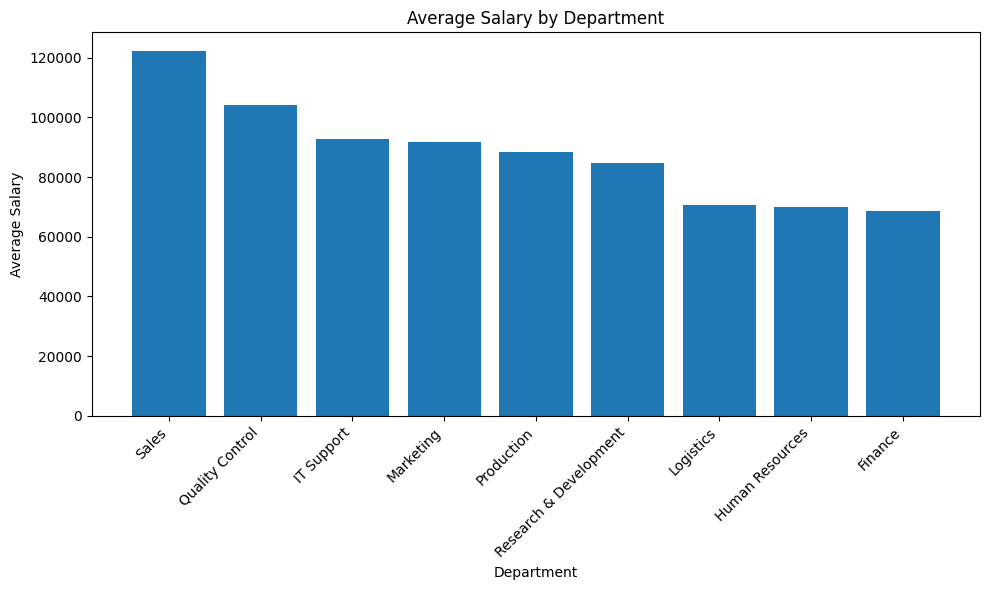

In [ ]:
# Create an average salary chart
import matplotlib.pyplot as plt

salary_chart = salary_analysis.sort_values(
    "Average_Salary", ascending=False
)

plt.figure(figsize=(10, 6))

plt.bar(
    salary_chart.index,
    salary_chart["Average_Salary"]
)

plt.title("Average Salary by Department")
plt.xlabel("Department")
plt.ylabel("Average Salary")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [ ]:
# Count employees hired each year
df["HireDate"] = pd.to_datetime(df["HireDate"], errors="coerce")

print(df["HireDate"].dtype)
print(df["HireDate"].head())

datetime64[ns]
0   2019-10-19
1   2019-06-16
2   2021-08-04
3   2018-10-09
4   2019-02-04
Name: HireDate, dtype: datetime64[ns]


In [ ]:
# Count employees hired each year
df["HireYear"] = df["HireDate"].dt.year

hiring_trends = df["HireYear"].value_counts().sort_index()

print(hiring_trends)

HireYear
2018    57
2019    60
2020    66
2021    61
2022    49
2023    53
2024    64
2025    50
2026    40
Name: count, dtype: int64


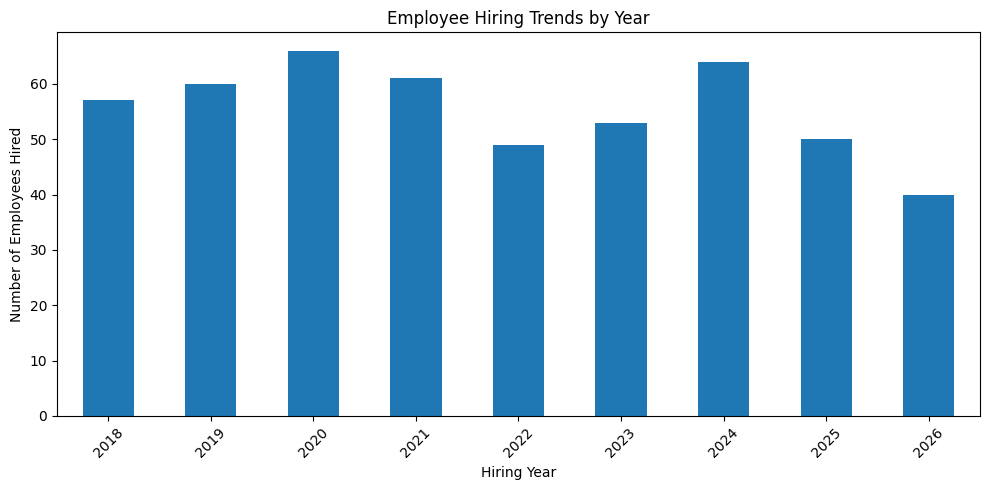

In [ ]:
# Create the hiring trends chart
plt.figure(figsize=(10, 5))

hiring_trends.plot(kind="bar")

plt.title("Employee Hiring Trends by Year")
plt.xlabel("Hiring Year")
plt.ylabel("Number of Employees Hired")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

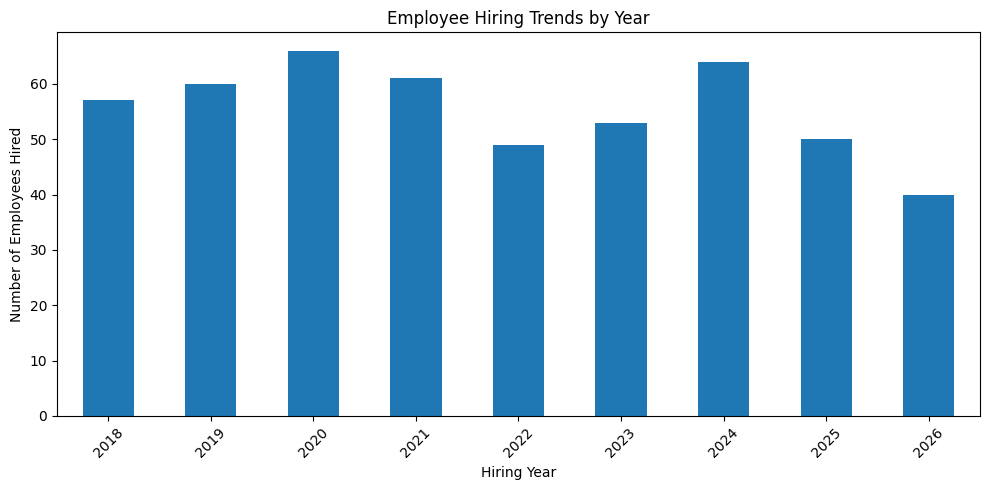

In [ ]:
# Visualise hiring trends
plt.figure(figsize=(10, 5))

hiring_trends.plot(kind="bar")

plt.title("Employee Hiring Trends by Year")
plt.xlabel("Hiring Year")
plt.ylabel("Number of Employees Hired")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
# Analyse employee gender distribution
gender_counts = df["Gender"].value_counts()

print(gender_counts)

Gender
Non-binary    175
Female        164
Male          161
Name: count, dtype: int64


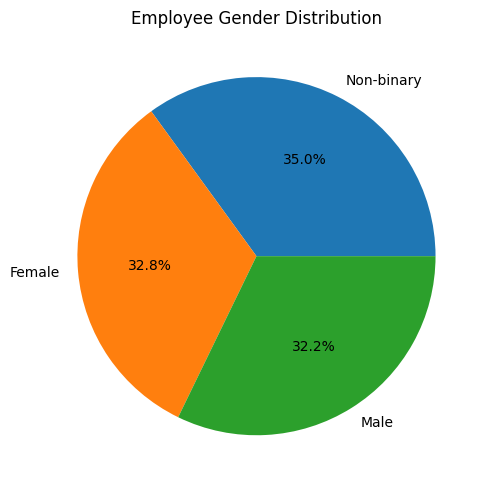

In [ ]:
# Create a gender distribution chart
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

gender_counts.plot(kind="pie", autopct="%1.1f%%")

plt.title("Employee Gender Distribution")
plt.ylabel("")

plt.tight_layout()
plt.show()

In [ ]:
# Calculate the active employee percentage
total_employees = len(df)

active_employees = (df["Status"] == "Active").sum()

active_percentage = (active_employees / total_employees) * 100

print("Total Employees:", total_employees)
print("Active Employees:", active_employees)
print("Active Employee Percentage:", round(active_percentage, 2), "%")

Total Employees: 500
Active Employees: 408
Active Employee Percentage: 81.6 %


In [ ]:
# Create a summary of your HR metrics
print("HR ANALYTICS SUMMARY")
print("--------------------")
print("Total Employees:", len(df))
print("Active Employees:", (df["Status"] == "Active").sum())
print("Terminated Employees:", (df["Status"] == "Terminated").sum())
print("Average Salary:", round(df["Salary"].mean(), 2))
print("Highest Salary:", df["Salary"].max())
print("Lowest Salary:", df["Salary"].min())
print("Average Performance Rating:", round(df["PerformanceRating"].mean(), 2))

HR ANALYTICS SUMMARY
--------------------
Total Employees: 500
Active Employees: 408
Terminated Employees: 92
Average Salary: 88262.66
Highest Salary: 179523
Lowest Salary: 55069
Average Performance Rating: 3.57


In [2]:
print("df" in globals())

False


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_excel(io.BytesIO(uploaded[filename]))

print("Dataset loaded successfully!")
print("Dataset size:", df.shape)

df.head()

Saving PNRao_HR_Analytics_Complete_Dataset.xlsx to PNRao_HR_Analytics_Complete_Dataset.xlsx
Dataset loaded successfully!
Dataset size: (500, 12)


,EmployeeID,FullName,Department,JobTitle,Email,Gender,HireDate,TerminationDate,Salary,ManagerID,PerformanceRating,Status
0,PNR-1001,Rohan Smith,Finance,Accountant,employee.1001@pnrao.com,Male,2019-10-19,NaN,65504,PNR-1302,3,Active
1,PNR-1002,Emma Wilson,Marketing,Marketing Coordinator,employee.1002@pnrao.com,Female,2019-06-16,NaN,81613,PNR-1081,4,Active
2,PNR-1003,Emma Jones,Production,Line Supervisor,employee.1003@pnrao.com,Female,2021-08-04,2022-04-24,82326,PNR-1148,5,Terminated
3,PNR-1004,Chris Brown,Sales,Regional Sales Manager,employee.1004@pnrao.com,Non-binary,2018-10-09,NaN,134925,NaN,2,Active
4,PNR-1005,Priya Wilson,Quality Control,QC Manager,employee.1005@pnrao.com,Male,2019-02-04,NaN,150999,NaN,4,Active


In [4]:
# KPI Summary
total_employees = len(df)
active_employees = (df["Status"] == "Active").sum()
terminated_employees = (df["Status"] == "Terminated").sum()

hr_summary = pd.DataFrame({
    "Metric": [
        "Total Employees",
        "Active Employees",
        "Terminated Employees",
        "Termination Rate (%)",
        "Average Salary",
        "Average Performance Rating"
    ],
    "Value": [
        total_employees,
        active_employees,
        terminated_employees,
        round(terminated_employees / total_employees * 100, 2),
        round(df["Salary"].mean(), 2),
        round(df["PerformanceRating"].mean(), 2)
    ]
})

hr_summary

,Metric,Value
0,Total Employees,500.00
1,Active Employees,408.00
2,Terminated Employees,92.00
3,Termination Rate (%),18.40
4,Average Salary,88262.66
5,Average Performance Rating,3.57


In [5]:
print(df.shape)

(500, 12)


In [6]:
total_employees = len(df)
active_employees = (df["Status"] == "Active").sum()
terminated_employees = (df["Status"] == "Terminated").sum()

hr_summary = pd.DataFrame({
    "Metric": [
        "Total Employees",
        "Active Employees",
        "Terminated Employees",
        "Active Percentage",
        "Termination Percentage",
        "Average Salary",
        "Average Performance Rating"
    ],
    "Value": [
        total_employees,
        active_employees,
        terminated_employees,
        round(active_employees / total_employees * 100, 2),
        round(terminated_employees / total_employees * 100, 2),
        round(df["Salary"].mean(), 2),
        round(df["PerformanceRating"].mean(), 2)
    ]
})

display(hr_summary)

,Metric,Value
0,Total Employees,500.00
1,Active Employees,408.00
2,Terminated Employees,92.00
3,Active Percentage,81.60
4,Termination Percentage,18.40
5,Average Salary,88262.66
6,Average Performance Rating,3.57


In [7]:
# Save KPI summary
hr_summary.to_excel("HR_Analytics_KPI_Summary.xlsx", index=False)

print("KPI summary saved successfully!")

KPI summary saved successfully!


In [8]:
# Download
from google.colab import files
files.download("HR_Analytics_KPI_Summary.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

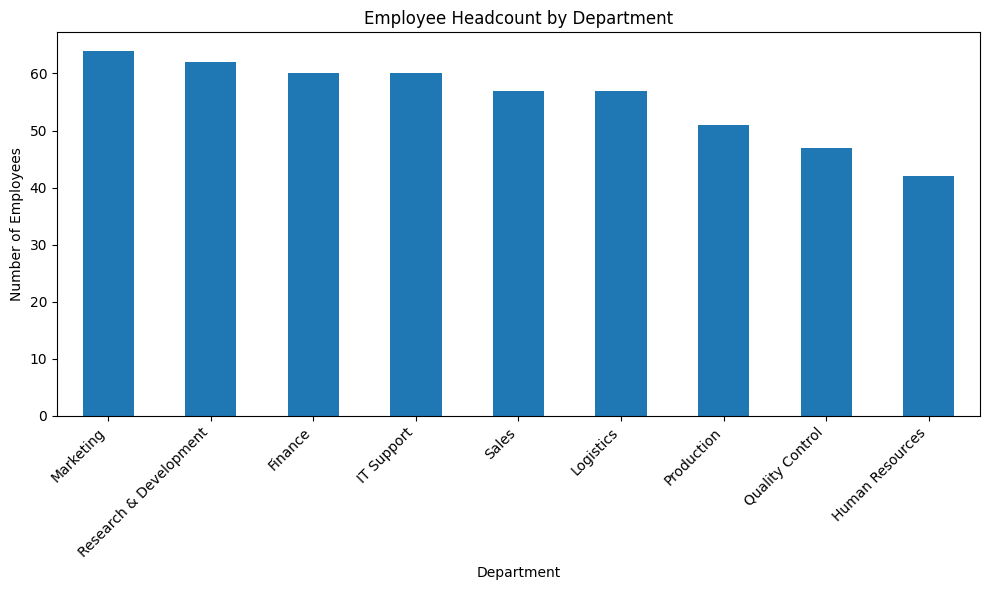

In [9]:
# Create a department-wise employee headcount chart
department_counts = df["Department"].value_counts()

plt.figure(figsize=(10, 6))
department_counts.plot(kind="bar")

plt.title("Employee Headcount by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [10]:
# Calculate department-wise average salary
department_salary = df.groupby("Department")["Salary"].mean().sort_values(
    ascending=False
)

print(department_salary.round(2))

Department
Sales                     122331.28
Quality Control           104053.15
IT Support                 92697.18
Marketing                  91697.36
Production                 88265.47
Research & Development     84786.02
Logistics                  70678.53
Human Resources            70033.38
Finance                    68485.65
Name: Salary, dtype: float64


In [11]:
# Save your department analysis
department_report = df.groupby("Department").agg(
    Employee_Count=("EmployeeID", "count"),
    Average_Salary=("Salary", "mean"),
    Total_Payroll=("Salary", "sum")
).round(2)

display(department_report)

department_report.to_excel("HR_Department_Analysis.xlsx")

,Employee_Count,Average_Salary,Total_Payroll
Department,,,
Finance,60,68485.65,4109139
Human Resources,42,70033.38,2941402
IT Support,60,92697.18,5561831
Logistics,57,70678.53,4028676
Marketing,64,91697.36,5868631
Production,51,88265.47,4501539
Quality Control,47,104053.15,4890498
Research & Development,62,84786.02,5256733
Sales,57,122331.28,6972883


In [12]:
# Generate HR business insights
total_employees = len(df)
active_employees = (df["Status"] == "Active").sum()
terminated_employees = (df["Status"] == "Terminated").sum()

termination_rate = terminated_employees / total_employees * 100

largest_department = df["Department"].value_counts().idxmax()

highest_salary_department = (
    df.groupby("Department")["Salary"].mean().idxmax()
)

average_salary = df["Salary"].mean()

print("HR BUSINESS INSIGHTS")
print("--------------------")
print(f"Total employees: {total_employees}")
print(f"Active employees: {active_employees}")
print(f"Terminated employees: {terminated_employees}")
print(f"Termination proportion: {termination_rate:.2f}%")
print(f"Largest department: {largest_department}")
print(f"Highest average salary department: {highest_salary_department}")
print(f"Overall average salary: {average_salary:.2f}")

HR BUSINESS INSIGHTS
--------------------
Total employees: 500
Active employees: 408
Terminated employees: 92
Termination proportion: 18.40%
Largest department: Marketing
Highest average salary department: Sales
Overall average salary: 88262.66


In [13]:
# Export the business insights
insights = pd.DataFrame({
    "Business Insight": [
        "Total Employees",
        "Active Employees",
        "Terminated Employees",
        "Termination Proportion (%)",
        "Largest Department",
        "Highest Average Salary Department",
        "Overall Average Salary"
    ],
    "Result": [
        total_employees,
        active_employees,
        terminated_employees,
        round(termination_rate, 2),
        largest_department,
        highest_salary_department,
        round(average_salary, 2)
    ]
})

insights.to_excel("HR_Business_Insights.xlsx", index=False)

print("Business insights report created successfully!")

Business insights report created successfully!


In [14]:
# Create a project folder with all reports and charts
import os

os.makedirs("HR_Analytics_Project", exist_ok=True)

print("Project folder created!")


Project folder created!


In [15]:
# Save your reports inside the project folder
hr_summary.to_excel(
    "HR_Analytics_Project/HR_Analytics_KPI_Summary.xlsx",
    index=False
)

department_report.to_excel(
    "HR_Analytics_Project/HR_Department_Analysis.xlsx"
)

insights.to_excel(
    "HR_Analytics_Project/HR_Business_Insights.xlsx",
    index=False
)

print("All reports saved in the project folder!")

All reports saved in the project folder!


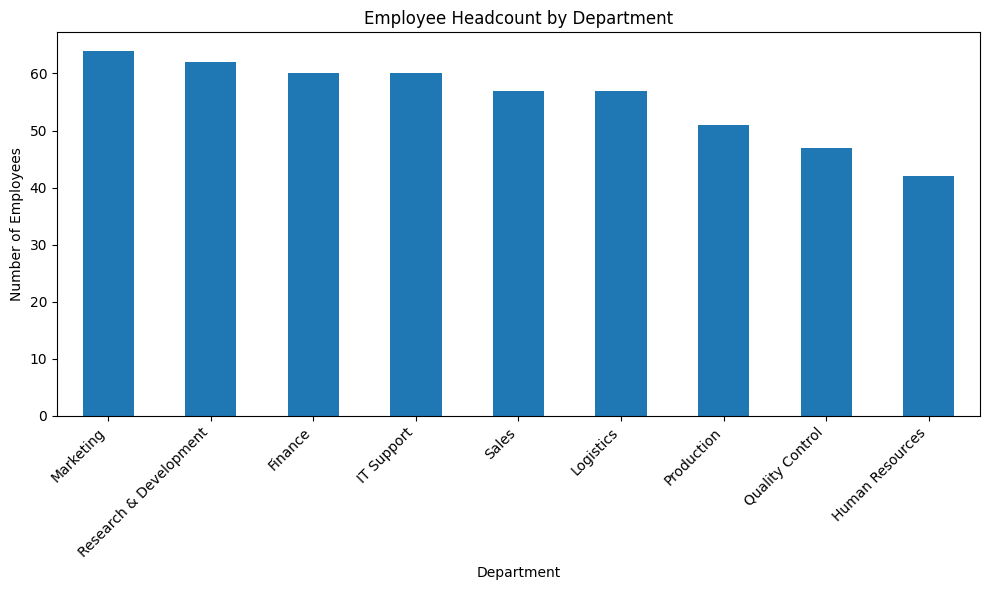

In [16]:
# Save your department chart as an image
plt.figure(figsize=(10, 6))

df["Department"].value_counts().plot(kind="bar")

plt.title("Employee Headcount by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.savefig(
    "HR_Analytics_Project/Department_Headcount.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
# Download your project folder
import shutil

shutil.make_archive(
    "HR_Analytics_Project",
    "zip",
    "HR_Analytics_Project"
)

from google.colab import files
files.download("HR_Analytics_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
# Create your README file
readme_content = """
# HR Analytics Project Using Python

## Project Overview
This project analyses employee data to identify workforce trends,
employee termination patterns, departmental headcount, salary
distribution, and performance ratings.

## Dataset
- Total records: 500 employees
- Total columns: 12
- Key fields: Department, JobTitle, Gender, HireDate,
  TerminationDate, Salary, PerformanceRating, and Status

## Tools and Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Google Colab

## Key Analysis
1. Employee headcount by department
2. Active and terminated employee analysis
3. Employee termination proportion
4. Department-wise salary analysis
5. Employee performance rating distribution
6. Gender distribution
7. Hiring trends by year

## Key Findings
- 500 employee records were analysed.
- 408 employees are marked Active.
- 92 employees are marked Terminated.
- The termination proportion is 18.4%.

## Project Objective
To demonstrate Python data analysis skills and generate
meaningful workforce insights that can support HR decision-making.

## Disclaimer
This project uses a practice dataset. The findings describe
the supplied data and should not be interpreted as conclusions
about a real organisation.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README file created successfully!")

README file created successfully!


In [19]:
# Download the README file
from google.colab import files
files.download("README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>